# **Mid Exam Text Mining**
## _Text Analysis and Classification of Game Reviews Using Different Text Representation Methods_

_**Project By:**_ <br>
Nama: Johanes Cedrick Wijaya <br>
NIM: 2702213801 <br>
Jurusan: Computer Science and Mathematics

==========================================================================================================================================================================================

## Case Overview
Ketika kita ingin mendownload sebuah game di Play Store, maka kita akan memilih game berdasarkan review dan rating game tersebut. Pada project ini, saya diminta untuk membangun sebuah model prediksi rating yang dapat digunakan pihak games untuk memprediksi konten dari sumber lain. Model prediksi rating akan dibangun menggunakan data teks sebagai fitur utama model. Pada project ini, akan dilakukan juga perbandingan performa dengan metode Text Representation dan Model Machine Learning yang berbeda.

==========================================================================================================================================================================================

## A. Data Scraping
Mengumpulkan data review games dengan tema yang anda suka dengan cara scrapping sebanyak 2000 data dengan berbagai nilai rating. Anda juga memutuskan untuk mengumpulkan data review dalam bahasa Inggris

In [543]:
from google_play_scraper import reviews, Sort
import pandas as pd

### A.1. PUBG Mobile

![pubg_play_store](images/pubg_play_store.png)

In [544]:
# results, _ = reviews(
#     'com.tencent.ig',
#     lang='en',  
#     country='us',
#     sort=Sort.NEWEST,
#     count=5000
# )

In [545]:
# pubg_df = pd.DataFrame(results)
# pubg_df

In [546]:
# pubg_df['score'].value_counts()

In [547]:
# pubg_df = pubg_df[['content', 'score']].copy()
# pubg_df['game'] = 'PUBG Mobile'
# pubg_df.head()

### A.2. Free Fire

![freefire_play_store](images/freefire_play_store.png)

In [548]:
# results, _ = reviews(
#     'com.dts.freefireth',
#     lang='en',  
#     country='us',
#     sort=Sort.NEWEST,
#     count=5000
# )

In [549]:
# ff_df = pd.DataFrame(results)
# ff_df

In [550]:
# ff_df['score'].value_counts()

In [551]:
# ff_df = ff_df[['content', 'score']].copy()
# ff_df['game'] = 'Free Fire'
# ff_df.head()

### A.3. Export to CSV

In [552]:
# pubg_df.to_csv('./data/pubg_reviews_5000.csv', index=False)
# ff_df.to_csv('./data/freefire_reviews_5000.csv', index=False)

==========================================================================================================================================================================================

## B. Exploratory Data Analysis (EDA)

### B.1. Data Info

In [553]:
pubg_csv = pd.read_csv('./data/pubg_reviews_5000.csv')
ff_csv = pd.read_csv('./data/freefire_reviews_5000.csv')

In [554]:
df = pd.concat([pubg_csv, ff_csv], ignore_index=True)

In [555]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  9999 non-null   object
 1   score    10000 non-null  int64 
 2   game     10000 non-null  object
dtypes: int64(1), object(2)
memory usage: 234.5+ KB


### B.2. Check Null Data

In [556]:
df.isnull().sum()

content    1
score      0
game       0
dtype: int64

In [557]:
df[df['content'].isnull()]

,content,score,game
5102,NaN,1,Free Fire


In [558]:
df = df.dropna(subset=['content'])

In [559]:
df.isnull().sum()

content    0
score      0
game       0
dtype: int64

### B.3. Check Duplicated Data

In [560]:
df.duplicated().sum()

np.int64(1686)

In [561]:
df['content'].duplicated().sum()

np.int64(2006)

In [562]:
df[df['content'].duplicated()]

,content,score,game
39,good,5,PUBG Mobile
89,good,5,PUBG Mobile
113,nice,5,PUBG Mobile
117,nice,5,PUBG Mobile
121,Very good,5,PUBG Mobile
...,...,...,...
9987,super,5,Free Fire
9989,wow,5,Free Fire
9996,very best game,5,Free Fire
9997,good,5,Free Fire


In [563]:
df['content'].value_counts().head()

content
good         277
good game    135
nice game    112
nice          98
best game     82
Name: count, dtype: int64

In [564]:
df = df.drop_duplicates(subset=['content'], keep='first')

### B.4. Downsampling

In [565]:
df['score'].value_counts()

score
5    5975
1    1145
4     458
3     226
2     189
Name: count, dtype: int64

In [566]:
df = pd.concat([
    df[df['score'] == 2].sample(189, random_state=42),
    df[df['score'] == 3].sample(226, random_state=42),
    df[df['score'] == 4].sample(295, random_state=42),
    df[df['score'] == 5].sample(850, random_state=42),
    df[df['score'] == 1].sample(440, random_state=42),
])

In [567]:
df['score'].value_counts()

score
5    850
1    440
4    295
3    226
2    189
Name: count, dtype: int64

### B.5. Data Visualization

In [568]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#F8FAFC",
        "axes.edgecolor": "#E5E7EB",

        "grid.color": "#E5E7EB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.7,

        "axes.labelcolor": "#334155",
        "xtick.color": "#475569",
        "ytick.color": "#475569",
        "text.color": "#334155",

        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlecolor": "#1E293B",

        "font.size": 11,
    }
)

sns.set_palette(
    'tab20'
)

#### B.5.1. Length Distribution

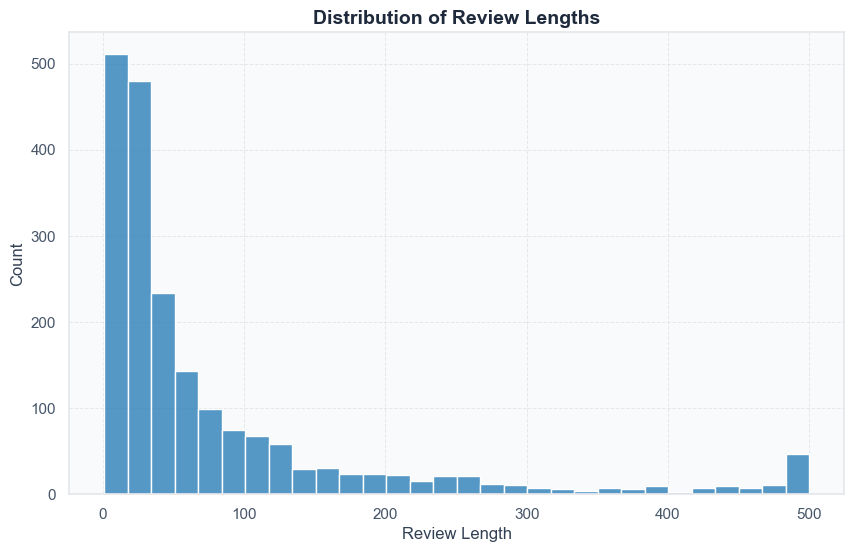

In [569]:
df['length'] = df['content'].apply(len)

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='length', bins=30)
plt.title('Distribution of Review Lengths')
plt.xlabel('Review Length')
plt.ylabel('Count')
plt.show()

In [570]:
df['length'].value_counts().sort_index(ascending=False).head(10)

length
500    12
499     6
498     4
497     4
496     1
495     1
494     3
493     4
492     2
491     1
Name: count, dtype: int64

In [571]:
df['length'].value_counts().sort_index(ascending=True).head(10)

length
1      6
2      5
3     20
4     19
5     20
6     20
7     31
8     32
9     39
10    40
Name: count, dtype: int64

In [572]:
df[df['length'] == 1]

,content,score,game,length
632,😱,3,PUBG Mobile,1
470,😍,5,PUBG Mobile,1
8171,💖,5,Free Fire,1
426,😠,1,PUBG Mobile,1
24,🙂,1,PUBG Mobile,1
1923,👎,1,PUBG Mobile,1


In [573]:
df[df['length'] == 2]

,content,score,game,length
9193,👍✨,3,Free Fire,2
7743,🥰🥰,5,Free Fire,2
1070,🫡🫡,5,PUBG Mobile,2
9243,😁😁,5,Free Fire,2
7913,💔🤬,1,Free Fire,2


In [574]:
df.sort_values(by='length', ascending=False).head(10)

,content,score,game,length
2067,I really like this game since I started playin...,2,PUBG Mobile,500
205,العبه جميله جدا جداجداجداجداجداجداجداجداجداجدا...,5,PUBG Mobile,500
3599,"Storm kills too fast, you literally can't appl...",1,PUBG Mobile,500
2683,"PUBG is amazing! This game is full of action, ...",5,PUBG Mobile,500
5510,What about hackers(dogs) & panels in this game...,1,Free Fire,500
2413,pubg is great before karfton and level infinit...,1,PUBG Mobile,500
2434,I would say that I have been playing this game...,5,PUBG Mobile,500
8479,"Dear garena free fire team, take the honour to...",3,Free Fire,500
2520,old lobby return @How gaming:Request to Bring ...,1,PUBG Mobile,500
6757,it's very goooooood I love it very much and I ...,1,Free Fire,500


#### B.5.2. Word Count Distribution

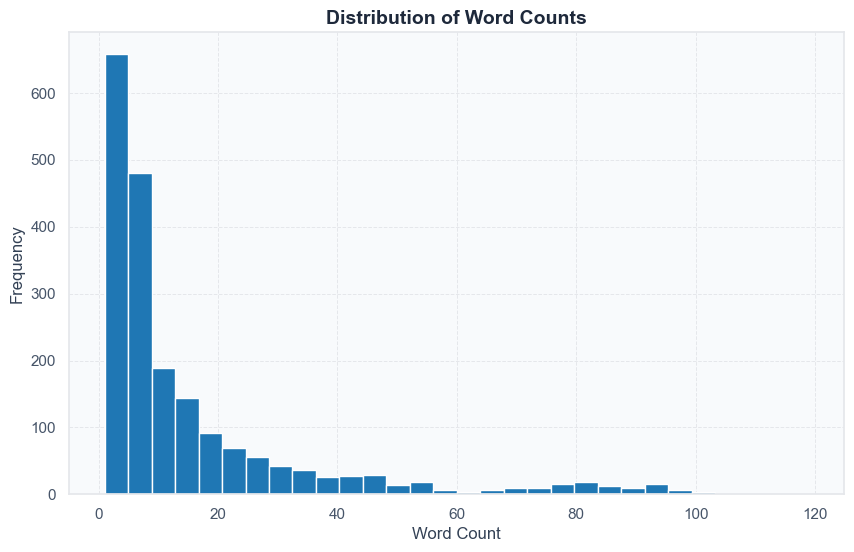

In [575]:
df['word_count'] = df['content'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 6))
plt.hist(df['word_count'], bins=30)
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.title('Distribution of Word Counts')
plt.show()

In [576]:
df['word_count'].value_counts().sort_index(ascending=False).head(10)

word_count
119    1
105    1
103    1
102    1
101    1
100    1
99     1
97     3
96     3
95     4
Name: count, dtype: int64

In [577]:
df['word_count'].value_counts().sort_index(ascending=True).head(10)

word_count
1     109
2     185
3     194
4     170
5     174
6     100
7     120
8      87
9      57
10     55
Name: count, dtype: int64

In [578]:
df[df['word_count'] == 1]

,content,score,game,length,word_count
8042,average,2,Free Fire,7,1
6034,"m,jazlan",2,Free Fire,8,1
5591,hacker!,2,Free Fire,7,1
981,Boring,2,PUBG Mobile,6,1
4725,pinkhigh,3,PUBG Mobile,8,1
...,...,...,...,...,...
1923,👎,1,PUBG Mobile,1,1
666,suck,1,PUBG Mobile,4,1
1641,pagal,1,PUBG Mobile,5,1
1497,lag,1,PUBG Mobile,3,1


In [579]:
df[df['word_count'] == 2]

,content,score,game,length,word_count
2455,just game,2,PUBG Mobile,9,2
8368,many glich,2,Free Fire,10,2
831,stupid game,2,PUBG Mobile,11,2
7796,الصراحه ماينفع,2,Free Fire,14,2
9146,skanin 🥰🥰🥰❤️❤️,2,Free Fire,14,2
...,...,...,...,...,...
1760,اسواء لعبة👎👎👎👎,1,PUBG Mobile,14,2
4523,💩💩💩💩💩💩💩💩💩💩💩 pubg,1,PUBG Mobile,16,2
2571,ff legenda,1,PUBG Mobile,10,2
4583,so bad😭,1,PUBG Mobile,7,2


In [580]:
df.sort_values(by='word_count', ascending=False).head(10)

,content,score,game,length,word_count
4947,and I don't want you want me anymore or you kn...,5,PUBG Mobile,483,119
2780,The game is very good and I really like playin...,3,PUBG Mobile,495,105
2475,after playing this game for 7 years. and spend...,1,PUBG Mobile,497,103
7352,the game is very enjoyable a d graphics is ver...,5,Free Fire,493,102
630,good game but there is some issues like fps dr...,5,PUBG Mobile,494,101
7115,greana please give us diamonds bundle like u g...,3,Free Fire,500,100
1870,Dear sir I don't understand what happen to my ...,2,PUBG Mobile,489,99
9334,i won't put 1 star... but still this is a bad ...,2,Free Fire,494,97
4119,I have played on mobile for years and its a ep...,4,PUBG Mobile,474,97
4929,Joke of a game or shadow of its former self. -...,1,PUBG Mobile,493,97


#### B.5.3. Wordcloud

In [581]:
from wordcloud import WordCloud

In [582]:
def generate_wordcloud(text, title):
    wc = WordCloud(width=1000, height=500, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(title, fontsize=20)
    plt.axis('off')
    plt.show()

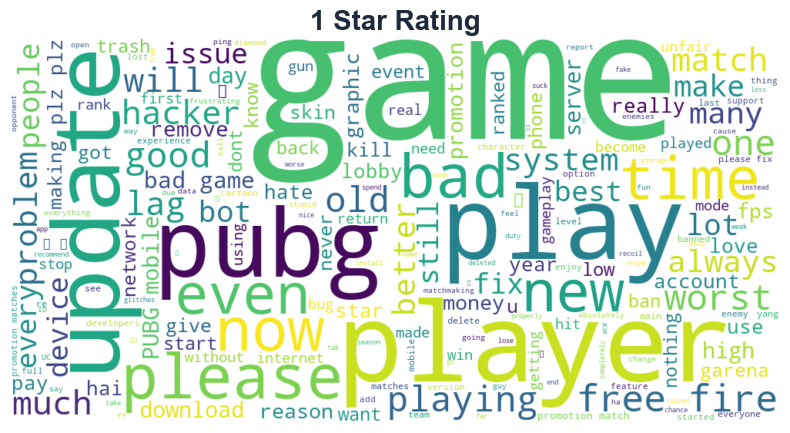

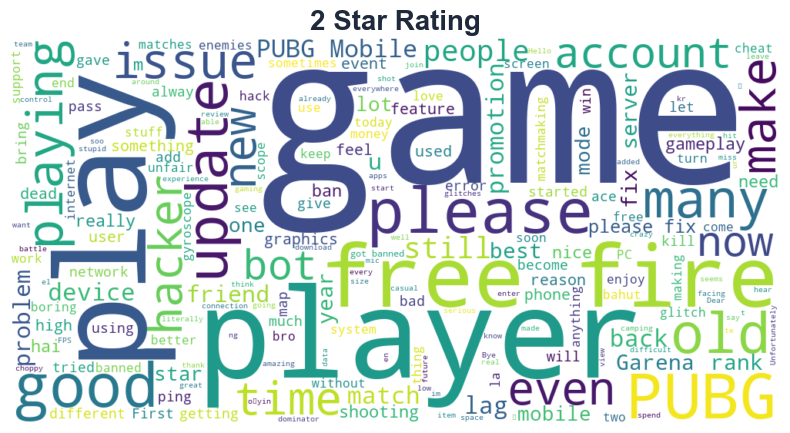

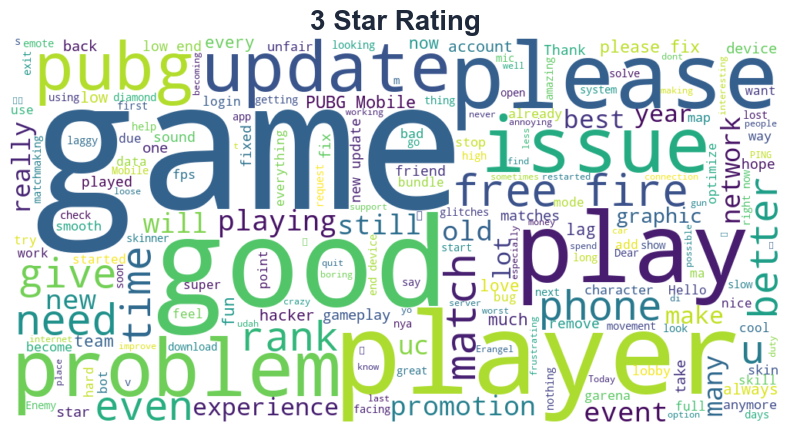

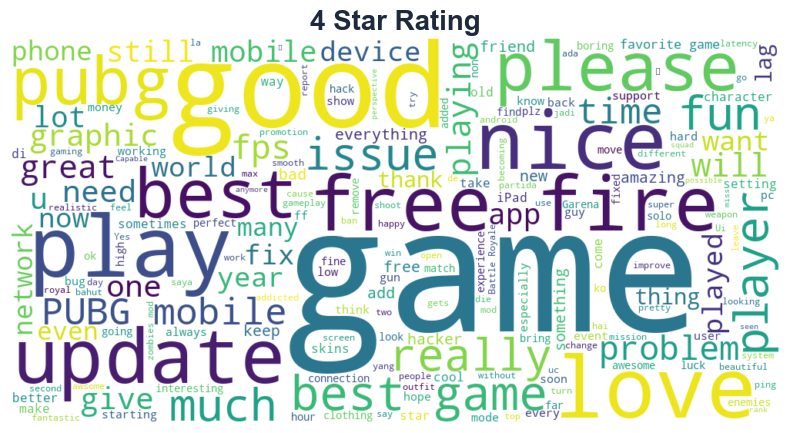

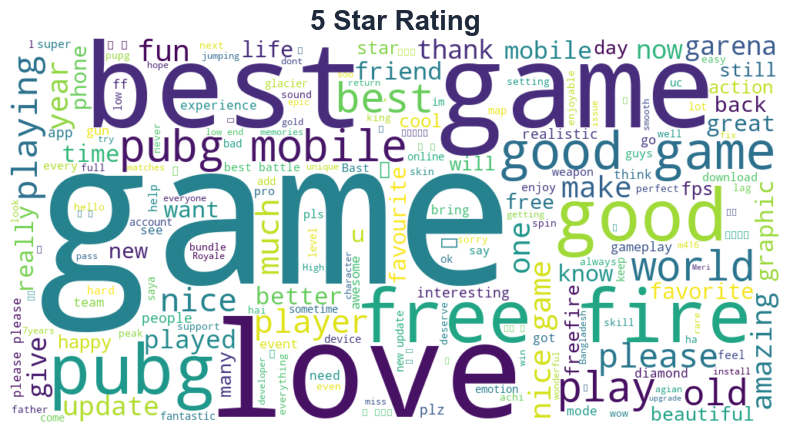

In [583]:
ratings = [1, 2, 3, 4, 5]

for r in ratings:
    generate_wordcloud(df[df['score'] == r]['content'].str.cat(sep=' '), f"{r} Star Rating")

#### B.5.4. Top Word Frequency

In [584]:
from sklearn.feature_extraction.text import CountVectorizer

def word_frequency(df, label):
    subset = df[df['score'] == label]

    vectorizer = CountVectorizer(stop_words='english')
    X = vectorizer.fit_transform(subset['content'])

    freq = X.sum(axis=0).A1
    vocab = vectorizer.get_feature_names_out()

    freq_df = pd.DataFrame({'word': vocab, 'frequency': freq})
    freq_df = freq_df.sort_values(by='frequency', ascending=False)

    return freq_df

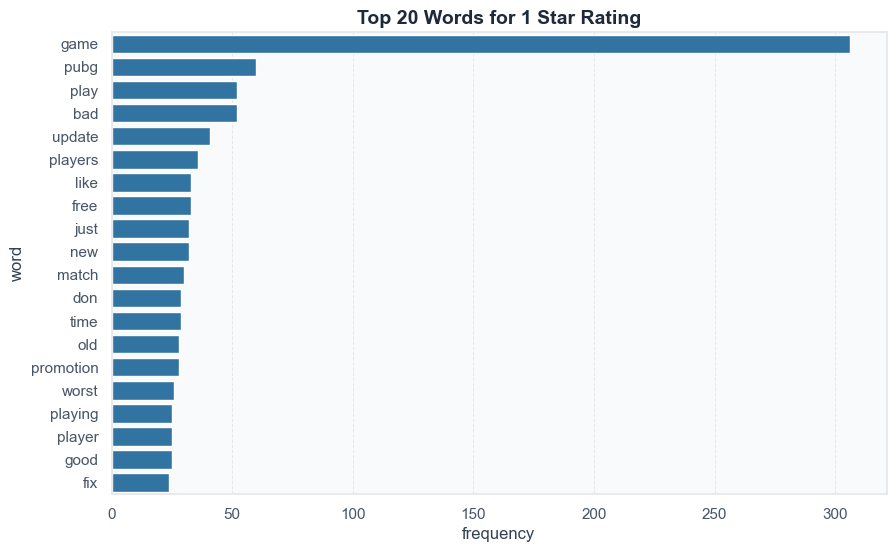

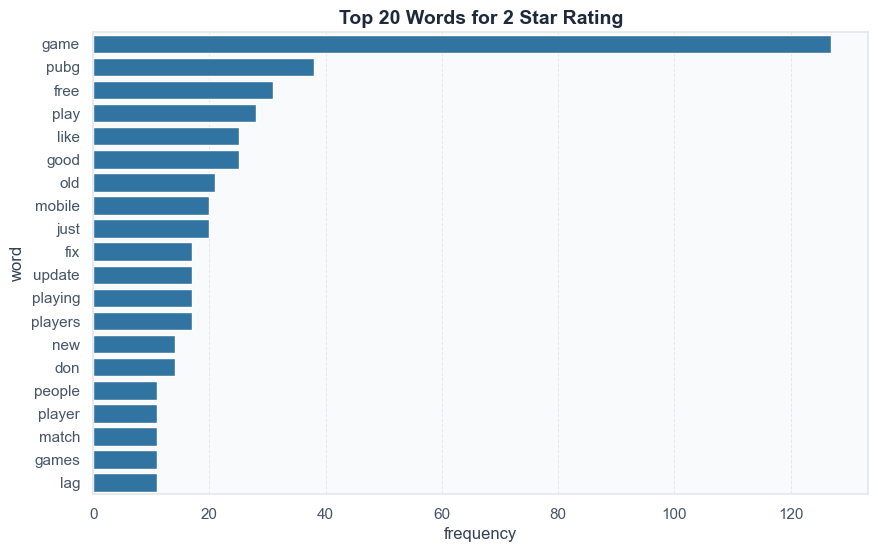

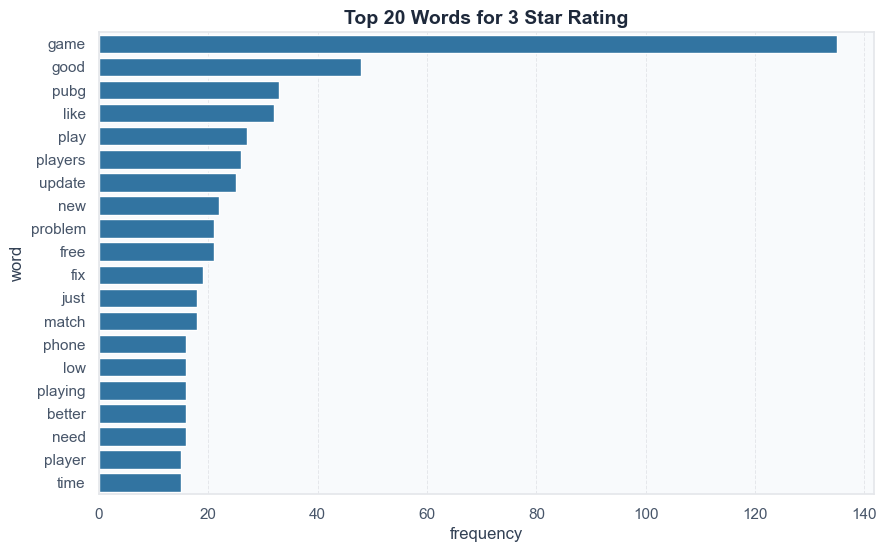

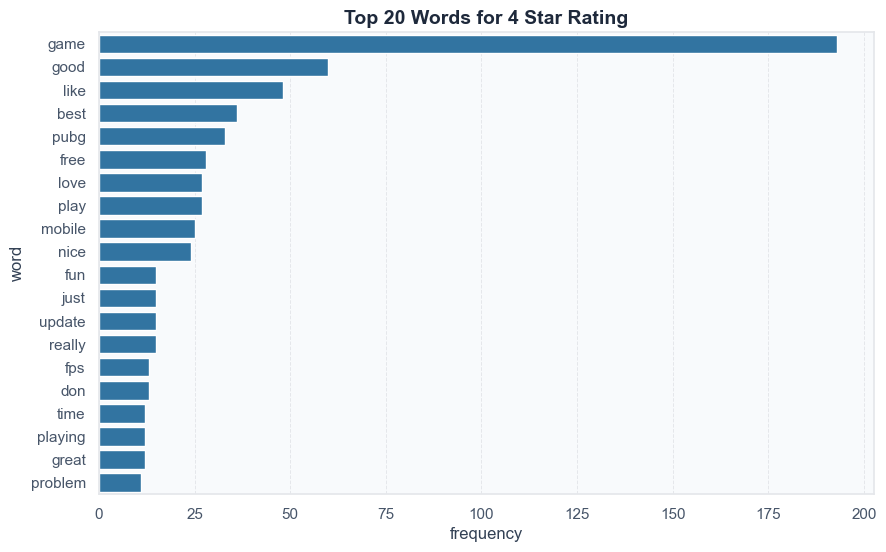

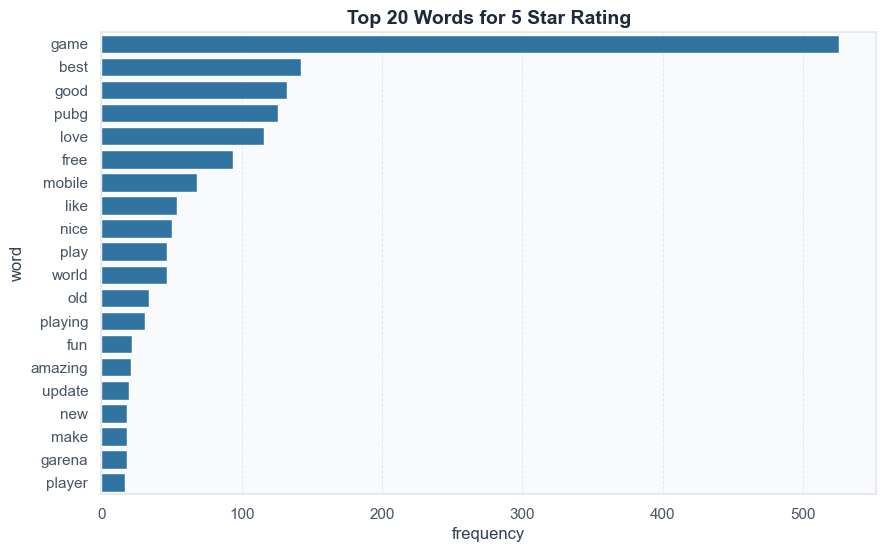

In [585]:
ratings = [1, 2, 3, 4, 5]

for r in ratings:
    freq_df = word_frequency(df, r)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=freq_df.head(20), x='frequency', y='word')
    plt.title(f'Top 20 Words for {r} Star Rating')
    plt.show()

#### B.5.5. Label Distribution

<Axes: ylabel='count'>

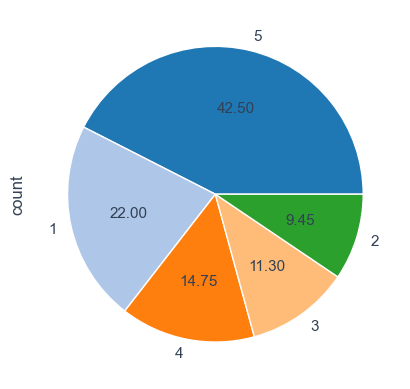

In [586]:
df['score'].value_counts().plot.pie(autopct='%.2f')

==========================================================================================================================================================================================

## C. Preprocessing

### C.1. Text Cleaning

In [587]:
import re

In [588]:
def text_cleaning(text):
    text = text.lower()
    text = re.sub(r'[\n\r\t]', ' ', text)
    text = text.replace("`", "'")
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [589]:
df = df.copy()
df['content'] = df['content'].apply(text_cleaning)
df.head()

,content,score,game,length,word_count
9849,no doubt it is a good game but in the evening ...,2,Free Fire,111,24
8584,please improve free fire s graphics or make a ...,2,Free Fire,264,48
1170,too much hackers you can t play a honest game ...,2,PUBG Mobile,123,23
1110,pubg mobile mahrbani kr ke pubg ka size kam kr...,2,PUBG Mobile,102,23
2982,whay slowly first open pubg,2,PUBG Mobile,27,5


### C.2. Handle Abbreviation

In [590]:
dictionary = {
    "aint": "is not",
    "arent": "are not",
    "cant": "cannot",
    "couldnt": "could not",
    "didnt": "did not",
    "doesnt": "does not",
    "dont": "do not",
    "hasnt": "has not",
    "havent": "have not",
    "hes": "he is",
    "ill": "i will",
    "im": "i am",
    "ive": "i have",
    "isnt": "is not",
    "its": "it is",
    "lets": "let us",
    "shell": "she will",
    "shes": "she is",
    "shouldnt": "should not",
    "thats": "that is",
    "theres": "there is",
    "theyre": "they are",
    "theyve": "they have",
    "were": "we are",
    "well": "we will",
    "werent": "were not",
    "whats": "what is",
    "whos": "who is",
    "wont": "will not",
    "wouldnt": "would not",
    "youre": "you are",
    "youve": "you have"
}

In [591]:
def handle_abbreviations(text):
    text = text.split()
    text = [dictionary[w] if w in dictionary else w for w in text]
    return ' '.join(text)

In [592]:
df['content'] = df['content'].apply(handle_abbreviations)

In [593]:
df.head()

,content,score,game,length,word_count
9849,no doubt it is a good game but in the evening ...,2,Free Fire,111,24
8584,please improve free fire s graphics or make a ...,2,Free Fire,264,48
1170,too much hackers you can t play a honest game ...,2,PUBG Mobile,123,23
1110,pubg mobile mahrbani kr ke pubg ka size kam kr...,2,PUBG Mobile,102,23
2982,whay slowly first open pubg,2,PUBG Mobile,27,5


### C.3. Data Splitting

In [594]:
from sklearn.model_selection import train_test_split

In [595]:
X = df[['content']]
y = df['score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### C.4. Tokenization

In [596]:
from nltk.tokenize import word_tokenize

In [597]:
X_train['tokens'] = [word_tokenize(text) for text in X_train['content']]
X_test['tokens'] = [word_tokenize(text) for text in X_test['content']]

In [598]:
X_train.head()

,content,tokens
7356,beautifull beautiful freddy fazbear s,"[beautifull, beautiful, freddy, fazbear, s]"
2987,pubg is the best game i play on my phone but w...,"[pubg, is, the, best, game, i, play, on, my, p..."
3063,,[]
4119,i have played on mobile for years and it is a ...,"[i, have, played, on, mobile, for, years, and,..."
4152,please bring back ipad perspective split scree...,"[please, bring, back, ipad, perspective, split..."


In [599]:
max_len = X_train['tokens'].apply(len).max()
max_len

np.int64(121)

In [600]:
vocab_size = len(set(word for tokens in X_train['tokens'] for word in tokens))
vocab_size

3525

In [601]:
X_train.head()

,content,tokens
7356,beautifull beautiful freddy fazbear s,"[beautifull, beautiful, freddy, fazbear, s]"
2987,pubg is the best game i play on my phone but w...,"[pubg, is, the, best, game, i, play, on, my, p..."
3063,,[]
4119,i have played on mobile for years and it is a ...,"[i, have, played, on, mobile, for, years, and,..."
4152,please bring back ipad perspective split scree...,"[please, bring, back, ipad, perspective, split..."


### C.5. Stopword Removal

In [602]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\johan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\johan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\johan\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [603]:
stopwords_additional = ['u', 'im', 'ur', 'dont', 'doin', 'ure', '4', '2', 'ive', 's', 't', 'll', 'd', 've', 'm']

In [604]:
stop_words_final = set(stopwords.words('english') + stopwords_additional)

In [605]:
def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in stop_words_final])

In [606]:
X_train['content'] = X_train['content'].apply(remove_stopwords)
X_test['content'] = X_test['content'].apply(remove_stopwords)

In [607]:
X_train.head()

,content,tokens
7356,beautifull beautiful freddy fazbear,"[beautifull, beautiful, freddy, fazbear, s]"
2987,pubg best game play phone invent promotion mat...,"[pubg, is, the, best, game, i, play, on, my, p..."
3063,,[]
4119,played mobile years epic fps great solo friend...,"[i, have, played, on, mobile, for, years, and,..."
4152,please bring back ipad perspective split scree...,"[please, bring, back, ipad, perspective, split..."


In [608]:
X_test.head()

,content,tokens
5928,ff,[ff]
3960,,[]
3364,restart years play pubg,"[now, restart, before, years, i, play, in, pubg]"
5492,good game say best action game world,"[it, s, very, good, game, i, can, say, this, i..."
488,good ago,"[very, good, ago]"


### C.6. Lemmatization

In [609]:
from nltk import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

In [610]:
def lemmatize(text):
    return ' '.join([lemmatizer.lemmatize(word) for word in text.split()])

In [611]:
X_train['content'] = X_train['content'].apply(lemmatize)
X_test['content'] = X_test['content'].apply(lemmatize)

In [612]:
def lemmatize_tokens(token_list):
    return [lemmatizer.lemmatize(word) for word in token_list]

In [613]:
X_train['tokens'] = X_train['tokens'].apply(lemmatize_tokens)
X_test['tokens'] = X_test['tokens'].apply(lemmatize_tokens)

In [614]:
X_train.head()

,content,tokens
7356,beautifull beautiful freddy fazbear,"[beautifull, beautiful, freddy, fazbear, s]"
2987,pubg best game play phone invent promotion mat...,"[pubg, is, the, best, game, i, play, on, my, p..."
3063,,[]
4119,played mobile year epic fps great solo friend ...,"[i, have, played, on, mobile, for, year, and, ..."
4152,please bring back ipad perspective split scree...,"[please, bring, back, ipad, perspective, split..."


### C.7. Visualization After Cleaning

#### C.7.1. Check Data 

In [615]:
df[df['content'] == '']

,content,score,game,length,word_count
8105,,2,Free Fire,12,3
9168,,2,Free Fire,15,3
364,,2,PUBG Mobile,61,11
7102,,2,Free Fire,48,10
1388,,2,PUBG Mobile,31,7
...,...,...,...,...,...
5782,,1,Free Fire,33,6
4135,,1,PUBG Mobile,14,3
8881,,1,Free Fire,23,4
1760,,1,PUBG Mobile,14,2


In [616]:
df = df[df['content'] != '']

In [617]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1863 entries, 9849 to 4188
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   content     1863 non-null   object
 1   score       1863 non-null   int64 
 2   game        1863 non-null   object
 3   length      1863 non-null   int64 
 4   word_count  1863 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 87.3+ KB


#### C.7.2. Length Distribution

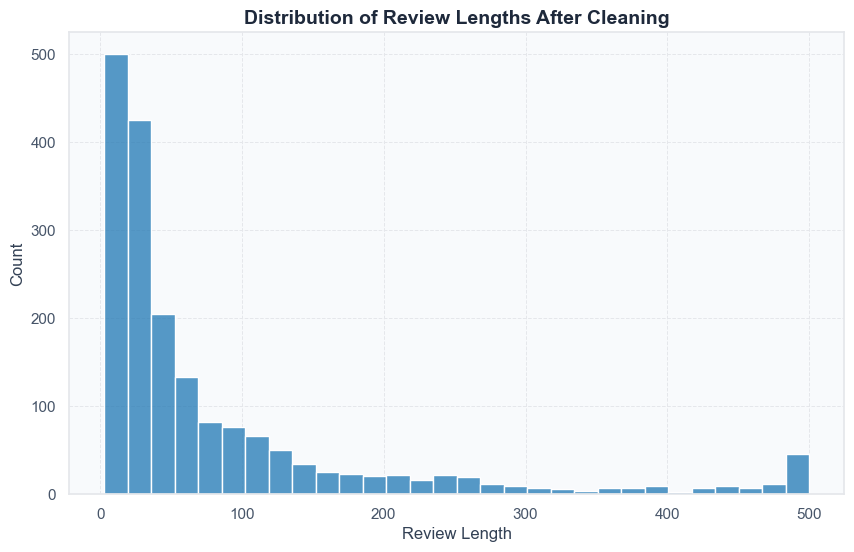

In [618]:
plt.figure(figsize=(10, 6))
sns.histplot(df['length'], bins=30)
plt.title('Distribution of Review Lengths After Cleaning')
plt.xlabel('Review Length')
plt.show()

#### C.7.3. Word Count Distribution

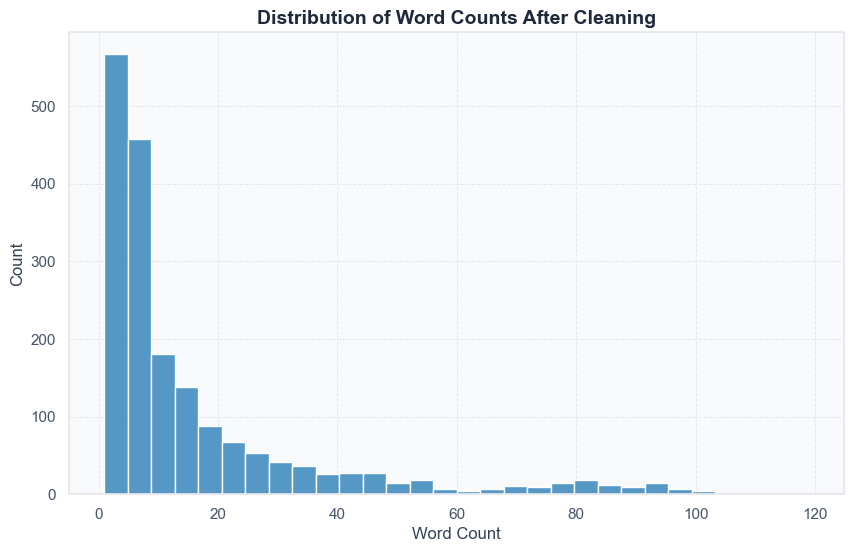

In [619]:
plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], bins=30)
plt.title('Distribution of Word Counts After Cleaning')
plt.xlabel('Word Count')
plt.show()

#### C.7.4. WordCloud After Cleaning

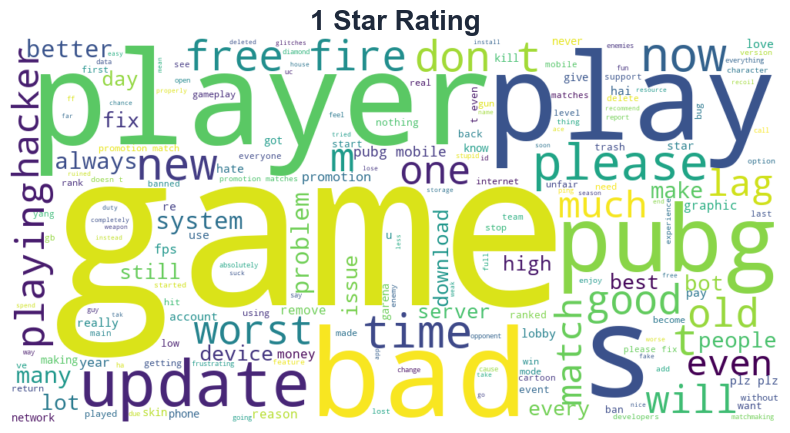

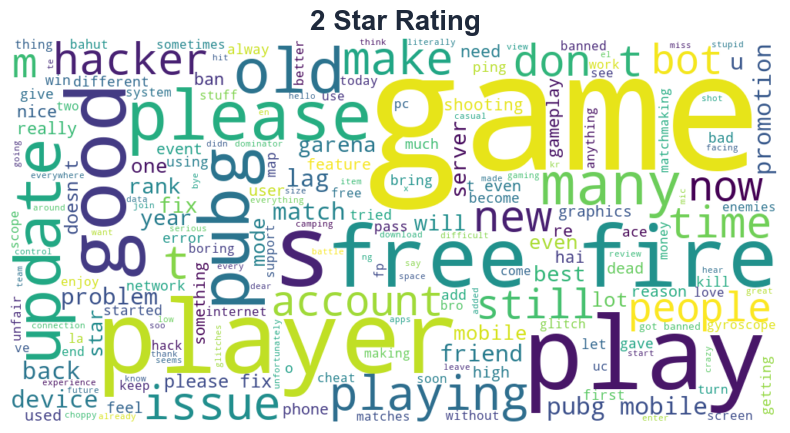

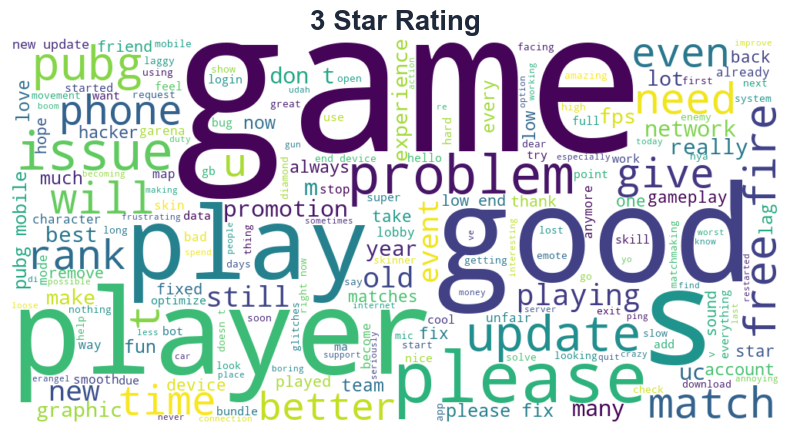

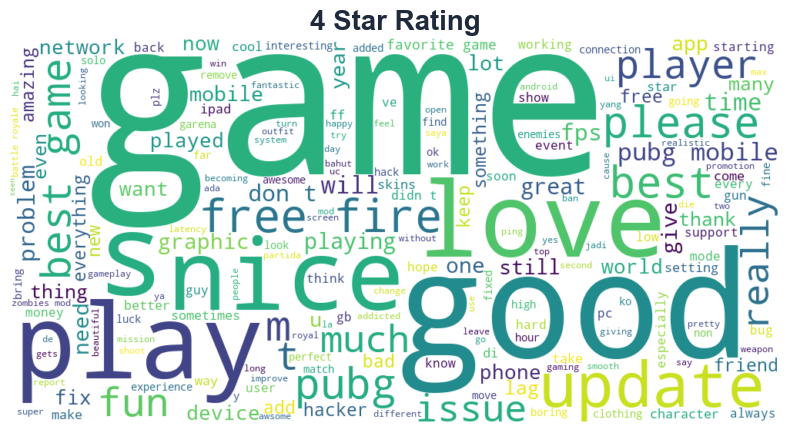

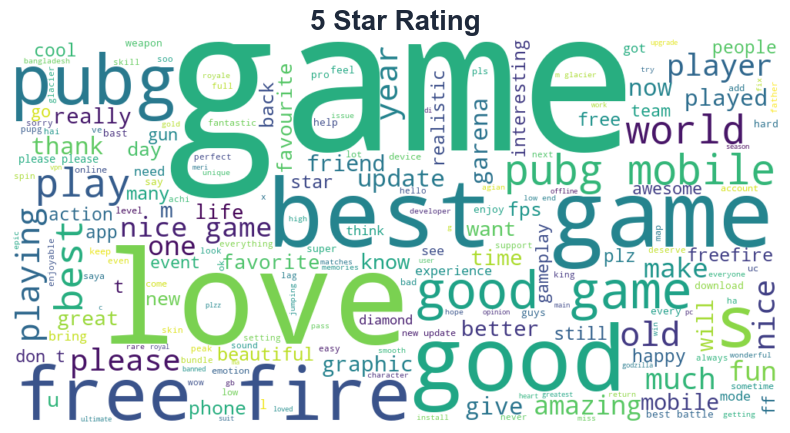

In [620]:
for r in ratings:
    generate_wordcloud(df[df['score'] == r]['content'].str.cat(sep=' '), f"{r} Star Rating")

==========================================================================================================================================================================================

## D. Text Representation

### D.1. TF-IDF

In [621]:
from sklearn.feature_extraction.text import TfidfVectorizer

#### D.1.1. Without Editing Parameter

In [622]:
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train['content'])
X_test_tfidf = vectorizer.transform(X_test['content'])

In [623]:
TFIDF = pd.DataFrame(X_train_tfidf.toarray(), columns=vectorizer.get_feature_names_out())
TFIDF.head()

,aa,aab,aaj,aapka,ab,abi,abilit,abilitie,ability,able,...,youtube,youtuber,yr,yy,zeke,zero,zombie,zone,zoon,zx
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### D.1.2. With Edit Parameter (min_df = 2)

In [624]:
vectorizer_new = TfidfVectorizer(min_df=2, max_features=5000)
X_train_tfidf = vectorizer_new.fit_transform(X_train['content'])
X_test_tfidf = vectorizer_new.transform(X_test['content'])

In [625]:
TFIDF_new = pd.DataFrame(X_train_tfidf.toarray(), columns=vectorizer_new.get_feature_names_out())
TFIDF_new.head()

,able,abnormal,absolute,absolutely,accept,account,accurate,ace,achcha,achi,...,yang,year,yes,yet,yg,yo,yok,youtuber,zombie,zone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.110274,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### D.2. Word2Vec

In [626]:
import gensim
from gensim.models import Word2Vec
import numpy as np

#### D.2.1. For Machine Learning

In [627]:
w2v_model = Word2Vec(
    sentences=X_train['tokens'],
    vector_size=100,
    window=5,
    min_count=2
)

def sentence_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

In [628]:
X_train_w2v = np.array([sentence_vector(tokens, w2v_model) for tokens in X_train['tokens']])
X_test_w2v = np.array([sentence_vector(tokens, w2v_model) for tokens in X_test['tokens']])

In [629]:
vector_rata_rata = X_train_w2v[0]

print(X_train['tokens'].iloc[0])
print(X_train_w2v[0])
print(X_train_w2v[0].shape)

['beautifull', 'beautiful', 'freddy', 'fazbear', 's']
[-0.04947776  0.16771097 -0.00200282  0.01091764  0.13215792 -0.35768434
  0.11119018  0.46476105 -0.12362061 -0.17317647 -0.07663872 -0.42386934
 -0.08460071  0.07912327  0.1642198  -0.20353772  0.12960729 -0.260396
 -0.07341213 -0.44570974  0.13649745  0.08163096  0.11113393 -0.08556245
 -0.09359179  0.0954721  -0.16887565 -0.16076691 -0.18144281 -0.06638777
  0.26550126 -0.00102916  0.0595483  -0.30370641 -0.03346782  0.2489475
  0.02720264 -0.19237839 -0.14362398 -0.29519671 -0.03875208 -0.26082912
 -0.17858025  0.05116915  0.24402535 -0.01089216 -0.22928055 -0.07624715
  0.28880736  0.15561     0.1404915  -0.19566581  0.08068632 -0.11787013
 -0.21781969  0.05592662  0.11387971  0.05873534 -0.26597205  0.04381482
  0.09699209 -0.00898262  0.08530582 -0.00232073 -0.33191988  0.33600205
  0.01667541  0.26044035 -0.3376264   0.35178384 -0.10852257  0.11910469
  0.21677878  0.07466622  0.22310393  0.11722582  0.02028077  0.09434902


In [630]:
print(w2v_model.wv.most_similar('game'))

[('but', 0.9997004866600037), ('is', 0.9996808171272278), ('in', 0.9996709823608398), ('the', 0.9996553063392639), ('and', 0.999638020992279), ('to', 0.9996281862258911), ('of', 0.9996236562728882), ('that', 0.9996213316917419), ('this', 0.9996200799942017), ('my', 0.9996196031570435)]


In [631]:
print(w2v_model.wv['game'])

[-0.09405212  0.29562494 -0.00873342  0.03166588  0.20465896 -0.6298121
  0.1977843   0.8378198  -0.2291651  -0.30950472 -0.12365586 -0.73772526
 -0.16000827  0.16200359  0.2803762  -0.34585953  0.2306834  -0.44437382
 -0.13881195 -0.78677464  0.23254497  0.14808908  0.20410457 -0.13442214
 -0.15467224  0.17994963 -0.2952031  -0.27144378 -0.32343158 -0.12217764
  0.45832446 -0.00445089  0.13288382 -0.54940826 -0.06442311  0.4380796
  0.06432937 -0.34385213 -0.2553349  -0.5254451  -0.09284201 -0.44492233
 -0.33745846  0.07966613  0.42596576 -0.01484009 -0.4100024  -0.12603281
  0.5082216   0.27834353  0.22122337 -0.35257816  0.12532541 -0.20306797
 -0.37511638  0.09448103  0.20158713  0.09096624 -0.4739571   0.08879867
  0.1717055  -0.01950676  0.14678928 -0.00369156 -0.5858942   0.59284693
  0.03792493  0.45318723 -0.61063516  0.63805693 -0.19533111  0.2356709
  0.36698776  0.10085828  0.38009274  0.19771217  0.03503042  0.15838663
 -0.33135927  0.02909849 -0.37448528 -0.13761124 -0.48

In [632]:
print(X_train_w2v.shape)

(1600, 100)


#### D.2.2. For Deep Learning

In [633]:
from keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

In [634]:
w2v_model_dl = Word2Vec(
    sentences=X_train['tokens'],
    vector_size=100,
    window=5,
    min_count=1,
)

In [635]:
tok = Tokenizer()
tok.fit_on_texts(X_train['tokens'])

In [636]:
X_train_seq = tok.texts_to_sequences(X_train['tokens'])
X_test_seq = tok.texts_to_sequences(X_test['tokens'])

In [637]:
max_len = X_train['tokens'].apply(len).max() + 10
max_len

np.int64(131)

In [638]:
X_train_padding = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_test_padding = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

In [639]:
vocab_size = len(tok.word_index) + 1
vocab_size

3316

In [640]:
embedding_matrix = np.zeros((vocab_size, 100))
for word, i in tok.word_index.items():
    if word in w2v_model_dl.wv:
        embedding_matrix[i] = w2v_model_dl.wv[word]

In [641]:
embedding_matrix

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [-0.24124254,  0.31261617,  0.06394611, ..., -0.32407936,
         0.10433099, -0.26948991],
       [-0.31032503,  0.39026648,  0.07601102, ..., -0.39285251,
         0.11666077, -0.33794075],
       ...,
       [-0.00884098,  0.02005467,  0.00137157, ..., -0.01134796,
         0.00407005, -0.01363022],
       [-0.00315494, -0.00301105, -0.00586237, ..., -0.00228671,
         0.00268243, -0.00524703],
       [ 0.00919405,  0.00105036,  0.00723795, ...,  0.00576684,
         0.00729026, -0.00599381]], shape=(3316, 100))

## E. Training Machine Learning Model

In [642]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils import class_weight

In [643]:
weight_ml = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_ml = dict(zip(np.unique(y_train), weight_ml))
class_weight_ml

{np.int64(1): np.float64(0.935672514619883),
 np.int64(2): np.float64(2.064516129032258),
 np.int64(3): np.float64(1.8285714285714285),
 np.int64(4): np.float64(1.3793103448275863),
 np.int64(5): np.float64(0.45977011494252873)}

### E.1. SVC

#### E.1.1. Using TFIDF

In [644]:
svc_model_tfidf = SVC(class_weight=class_weight_ml, random_state=42)
svc_model_tfidf.fit(X_train_tfidf, y_train)
y_pred_svc_tfidf = svc_model_tfidf.predict(X_test_tfidf)

In [645]:
print("Classification Report Using SVC (TFIDF):")
print(classification_report(y_test, y_pred_svc_tfidf))

Classification Report Using SVC (TFIDF):
              precision    recall  f1-score   support

           1       0.44      0.55      0.49        98
           2       0.15      0.12      0.13        34
           3       0.14      0.08      0.10        51
           4       0.23      0.25      0.24        63
           5       0.65      0.65      0.65       154

    accuracy                           0.45       400
   macro avg       0.32      0.33      0.32       400
weighted avg       0.42      0.45      0.43       400



#### E.1.2. Using Word2Vec

In [646]:
svc_model_w2v = SVC(class_weight=class_weight_ml, random_state=42)
svc_model_w2v.fit(X_train_w2v, y_train)
y_pred_svc_w2v = svc_model_w2v.predict(X_test_w2v)

In [647]:
print("Classification Report Using SVC (Word2Vec):")
print(classification_report(y_test, y_pred_svc_w2v))

Classification Report Using SVC (Word2Vec):
              precision    recall  f1-score   support

           1       0.33      0.16      0.22        98
           2       0.09      0.76      0.15        34
           3       0.00      0.00      0.00        51
           4       0.00      0.00      0.00        63
           5       0.41      0.13      0.20       154

    accuracy                           0.15       400
   macro avg       0.16      0.21      0.11       400
weighted avg       0.24      0.15      0.14       400



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

#### E.1.3. Hyperparameter Tuning

In [648]:
from sklearn.model_selection import GridSearchCV

param_grid_svc ={
    'C': [0.1, 1, 10, 100, 1000],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

##### E.1.3.1. Using TFIDF

In [649]:
svc_model_ht_tfidf = SVC(class_weight=class_weight_ml, random_state=42)
grid_search_svc_tfidf = GridSearchCV(estimator=svc_model_ht_tfidf, param_grid=param_grid_svc, cv=5, n_jobs=-1)
grid_search_svc_tfidf.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(class_wei...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is al

In [650]:
best_model_svc_tfidf = grid_search_svc_tfidf.best_estimator_
y_pred_best_svc_tfidf = best_model_svc_tfidf.predict(X_test_tfidf)

In [651]:
print("Classification Report Using Best SVC (TFIDF):")
print(classification_report(y_test, y_pred_best_svc_tfidf))

Classification Report Using Best SVC (TFIDF):
              precision    recall  f1-score   support

           1       0.45      0.50      0.47        98
           2       0.15      0.06      0.09        34
           3       0.11      0.04      0.06        51
           4       0.28      0.19      0.23        63
           5       0.55      0.78      0.65       154

    accuracy                           0.46       400
   macro avg       0.31      0.31      0.30       400
weighted avg       0.39      0.46      0.42       400



<Figure size 600x600 with 0 Axes>

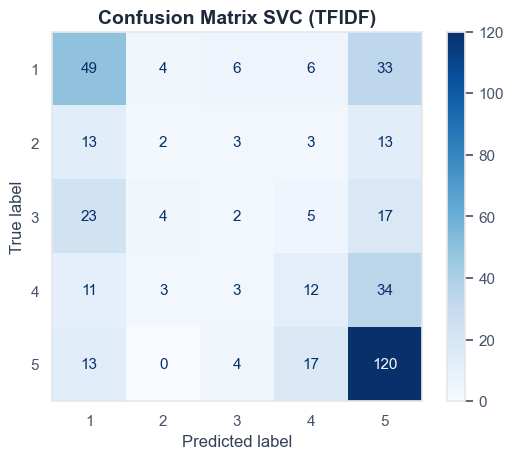

In [652]:
cm_svc_tfidf = confusion_matrix(y_test, y_pred_best_svc_tfidf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_tfidf, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix SVC (TFIDF)")
plt.show()

##### E.1.3.2. Using Word2Vec

In [653]:
svc_model_ht_w2c = SVC(class_weight=class_weight_ml, random_state=42)
grid_search_svc_w2v = GridSearchCV(estimator=svc_model_ht_w2c, param_grid=param_grid_svc, cv=5, n_jobs=-1)
grid_search_svc_w2v.fit(X_train_w2v, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(class_wei...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is al

In [654]:
best_model_svc_w2v = grid_search_svc_w2v.best_estimator_
y_pred_best_svc_w2v = best_model_svc_w2v.predict(X_test_w2v)

In [655]:
print("Classification Report Using Best SVC (Word2Vec):")
print(classification_report(y_test, y_pred_best_svc_w2v))

Classification Report Using Best SVC (Word2Vec):
              precision    recall  f1-score   support

           1       0.42      0.19      0.27        98
           2       0.10      0.32      0.15        34
           3       0.25      0.29      0.27        51
           4       0.23      0.19      0.21        63
           5       0.61      0.51      0.56       154

    accuracy                           0.34       400
   macro avg       0.32      0.30      0.29       400
weighted avg       0.41      0.34      0.36       400



<Figure size 600x600 with 0 Axes>

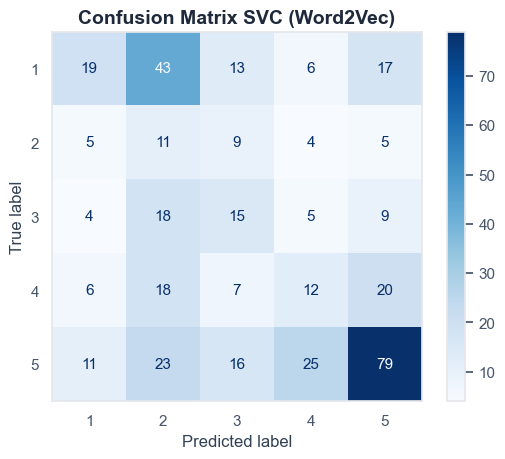

In [656]:
cm_svc_w2v = confusion_matrix(y_test, y_pred_best_svc_w2v)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_w2v, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix SVC (Word2Vec)")
plt.show()

### E.2. Random Forest

#### E.2.1. Using TFIDF

In [657]:
ranfor_model_tfidf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight=class_weight_ml)
ranfor_model_tfidf.fit(X_train_tfidf, y_train)
y_pred_ranfor_tfidf = ranfor_model_tfidf.predict(X_test_tfidf)

In [658]:
print("Classification Report Using Random Forest (TFIDF):")
print(classification_report(y_test, y_pred_ranfor_tfidf))

Classification Report Using Random Forest (TFIDF):
              precision    recall  f1-score   support

           1       0.41      0.34      0.37        98
           2       0.08      0.03      0.04        34
           3       0.13      0.04      0.06        51
           4       0.28      0.08      0.12        63
           5       0.50      0.89      0.64       154

    accuracy                           0.45       400
   macro avg       0.28      0.27      0.25       400
weighted avg       0.36      0.45      0.37       400



#### E.2.2. Using Word2Vec

In [659]:
ranfor_model_w2v = RandomForestClassifier(n_estimators=100, random_state=42, class_weight=class_weight_ml)
ranfor_model_w2v.fit(X_train_w2v, y_train)
y_pred_ranfor_w2v = ranfor_model_w2v.predict(X_test_w2v)

In [660]:
print("Classification Report Using Random Forest (Word2Vec):")
print(classification_report(y_test, y_pred_ranfor_w2v))

Classification Report Using Random Forest (Word2Vec):
              precision    recall  f1-score   support

           1       0.39      0.24      0.30        98
           2       0.22      0.06      0.09        34
           3       0.08      0.02      0.03        51
           4       0.17      0.08      0.11        63
           5       0.45      0.84      0.58       154

    accuracy                           0.40       400
   macro avg       0.26      0.25      0.22       400
weighted avg       0.32      0.40      0.33       400



#### E.2.3. Hyperparameter Tuning

In [661]:
param_grid_ranfor = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

##### E.2.3.1. Using TFIDF

In [662]:
ranfor_model_ht_tfidf = RandomForestClassifier(random_state=42, class_weight=class_weight_ml)
grid_search_ranfor_tfidf = GridSearchCV(estimator=ranfor_model_ht_tfidf, param_grid=param_grid_ranfor, cv=5, n_jobs=-1)
grid_search_ranfor_tfidf.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter ca

In [663]:
best_model_ranfor_tfidf = grid_search_ranfor_tfidf.best_estimator_
y_pred_best_ranfor_tfidf = best_model_ranfor_tfidf.predict(X_test_tfidf)

In [664]:
print("Classification Report Using Best Random Forest (TFIDF):")
print(classification_report(y_test, y_pred_best_ranfor_tfidf))

Classification Report Using Best Random Forest (TFIDF):
              precision    recall  f1-score   support

           1       0.40      0.35      0.37        98
           2       0.25      0.06      0.10        34
           3       0.06      0.02      0.03        51
           4       0.12      0.03      0.05        63
           5       0.49      0.88      0.63       154

    accuracy                           0.43       400
   macro avg       0.27      0.27      0.24       400
weighted avg       0.34      0.43      0.35       400



<Figure size 600x600 with 0 Axes>

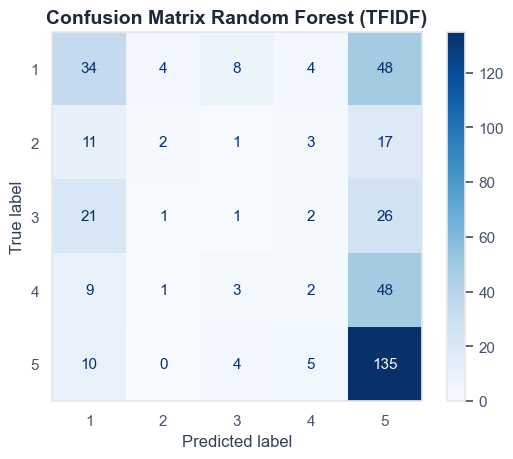

In [665]:
cm_rf_tfidf = confusion_matrix(y_test, y_pred_best_ranfor_tfidf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_tfidf, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Random Forest (TFIDF)")
plt.show()

##### E.2.3.2. Using Word2Vec

In [666]:
ranfor_model_ht_w2v = RandomForestClassifier(random_state=42, class_weight=class_weight_ml)
grid_search_ranfor_w2v = GridSearchCV(estimator=ranfor_model_ht_w2v, param_grid=param_grid_ranfor, cv=5, n_jobs=-1)
grid_search_ranfor_w2v.fit(X_train_w2v, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter ca

In [667]:
best_model_ranfor_w2v = grid_search_ranfor_w2v.best_estimator_
y_pred_best_ranfor_w2v = best_model_ranfor_w2v.predict(X_test_w2v)

In [668]:
print("Classification Report Using Best Random Forest (Word2Vec):")
print(classification_report(y_test, y_pred_best_ranfor_w2v))

Classification Report Using Best Random Forest (Word2Vec):
              precision    recall  f1-score   support

           1       0.40      0.24      0.30        98
           2       0.25      0.06      0.10        34
           3       0.09      0.02      0.03        51
           4       0.18      0.06      0.09        63
           5       0.44      0.86      0.59       154

    accuracy                           0.41       400
   macro avg       0.27      0.25      0.22       400
weighted avg       0.33      0.41      0.33       400



<Figure size 600x600 with 0 Axes>

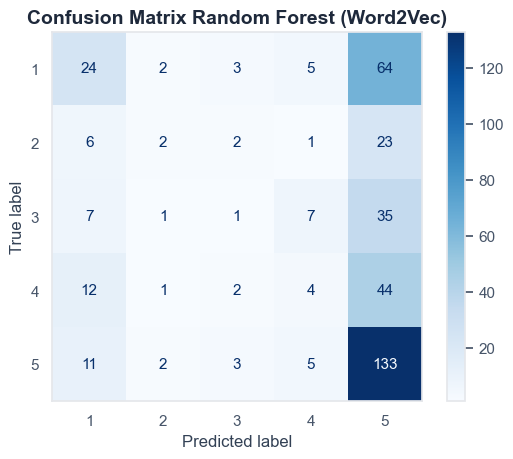

In [669]:
cm_rf_w2v = confusion_matrix(y_test, y_pred_best_ranfor_w2v)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_w2v, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Random Forest (Word2Vec)")
plt.show()

## F. Deep Learning Classification

### F.1. LSTM

In [692]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.initializers import Constant

In [693]:
model_dl_w2v = Sequential([
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=100,
        embeddings_initializer=Constant(embedding_matrix),
        input_length=max_len,
        trainable=True
    ),
    layers.LSTM(64),
    layers.BatchNormalization(),
    layers.Dense(5, activation='softmax')
])

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [694]:
model_dl_w2v.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dl_w2v.build(input_shape=(None, max_len))

In [695]:
model_dl_w2v.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 131, 100)       │       331,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 374,421 (1.43 MB)

 Trainable params: 374,293 (1.43 MB)

 Non-trainable params: 128 (512.00 B)

In [696]:
label_mapping = {
    1: 0,
    2: 1,
    3: 2,
    4: 3,
    5: 4
}

y_train_dl = y_train.map(label_mapping)
y_test_dl = y_test.map(label_mapping)

In [697]:
weight_dl = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_dl),
    y=y_train_dl
)
class_weight_dl = dict(zip(np.unique(y_train_dl), weight_dl))
class_weight_dl

{np.int64(0): np.float64(0.935672514619883),
 np.int64(1): np.float64(2.064516129032258),
 np.int64(2): np.float64(1.8285714285714285),
 np.int64(3): np.float64(1.3793103448275863),
 np.int64(4): np.float64(0.45977011494252873)}

In [698]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [699]:
history_dl_w2v = model_dl_w2v.fit(
    X_train_padding, y_train_dl,
    validation_split=0.1,
    epochs=10,
    batch_size=8,
    callbacks=[early_stop],
    # class_weight=class_weight_dl
)

Epoch 1/10


180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.4215 - loss: 1.4951 - val_accuracy: 0.4688 - val_loss: 1.4346
Epoch 2/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.4313 - loss: 1.4443 - val_accuracy: 0.4688 - val_loss: 1.4328
Epoch 3/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.4313 - loss: 1.4440 - val_accuracy: 0.1688 - val_loss: 1.5463
Epoch 4/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.4313 - loss: 1.4444 - val_accuracy: 0.4625 - val_loss: 1.5088
Epoch 5/10
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.4313 - loss: 1.4440 - val_accuracy: 0.4625 - val_loss: 1.4398


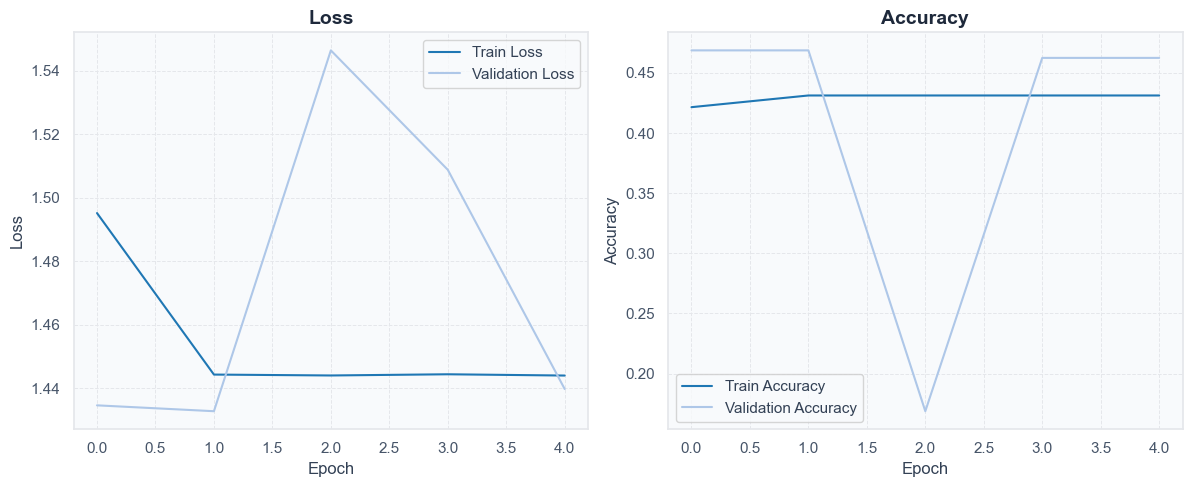

In [700]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(history_dl_w2v.history['loss'], label='Train Loss')
plt.plot(history_dl_w2v.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(history_dl_w2v.history['accuracy'], label='Train Accuracy')
plt.plot(history_dl_w2v.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [701]:
y_pred_dl_w2v = model_dl_w2v.predict(X_test_padding)
y_pred_dl_w2v_classes = np.argmax(y_pred_dl_w2v, axis=1) + 1

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


In [702]:
print("Classification Report Using LSTM (Word2Vec):")
print(classification_report(y_test, y_pred_dl_w2v_classes))

Classification Report Using LSTM (Word2Vec):
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        98
           2       0.00      0.00      0.00        34
           3       0.00      0.00      0.00        51
           4       0.00      0.00      0.00        63
           5       0.39      1.00      0.56       154

    accuracy                           0.39       400
   macro avg       0.08      0.20      0.11       400
weighted avg       0.15      0.39      0.21       400



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

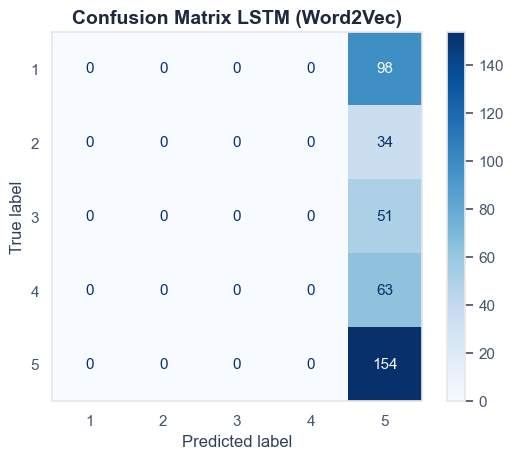

In [703]:
cm_dl_w2v = confusion_matrix(y_test, y_pred_dl_w2v_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dl_w2v, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix LSTM (Word2Vec)")
plt.show()

In [682]:
# model_dl_w2v.save('model_dl_w2v.keras')

### F.2. Hyperparameter Tuning

In [683]:
import keras_tuner as kt

In [684]:
def lstm_builder(hp):
    model = Sequential()
    model.add(layers.Embedding(
        input_dim=vocab_size,
        output_dim=100,
        embeddings_initializer=Constant(embedding_matrix),
        input_length=max_len,
        trainable=True
    ))

    hp_units = hp.Int('units', min_value=32, max_value=128, step=32)
    model.add(layers.LSTM(hp_units))
    model.add(layers.BatchNormalization())
    model.add(layers.Dense(5, activation='softmax'))
    
    hp_lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [685]:
tuner = kt.GridSearch(
    hypermodel=lstm_builder,
    objective='val_loss',
    max_trials=10,
    executions_per_trial=1,
    directory='lstm_tuning_data_baru',
    project_name='lstm_w2v_data_baru'
)

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [686]:
tuner.search(
    X_train_padding, y_train_dl,
    validation_split=0.1,
    epochs=10,
    batch_size=8,
    verbose=1,
    class_weight=class_weight_dl
    # callbacks=[early_stop],
)

Trial 10 Complete [00h 01m 15s]
val_loss: 1.5802065134048462

Best val_loss So Far: 1.4575921297073364
Total elapsed time: 00h 08m 44s


In [687]:
best = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best LSTM Units: ", best.get('units'))
print("Best Learning Rate: ", best.get('learning_rate'))

Best LSTM Units:  32
Best Learning Rate:  0.001


In [688]:
best_model_dl_w2v = tuner.get_best_models(num_models=1)[0]

c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [689]:
y_pred_dl_w2v_best = best_model_dl_w2v.predict(X_test_padding)
y_pred_dl_w2v_best_classes = np.argmax(y_pred_dl_w2v_best, axis=1) + 1

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


In [690]:
print("Classification Report Using Best LSTM (Word2Vec):")
print(classification_report(y_test, y_pred_dl_w2v_best_classes))

Classification Report Using Best LSTM (Word2Vec):
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        98
           2       0.00      0.00      0.00        34
           3       0.00      0.00      0.00        51
           4       0.00      0.00      0.00        63
           5       0.39      1.00      0.56       154

    accuracy                           0.39       400
   macro avg       0.08      0.20      0.11       400
weighted avg       0.15      0.39      0.21       400



c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\johan\Bina Nusantara\Semester 5\Deep Learning\Code\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

<Figure size 600x600 with 0 Axes>

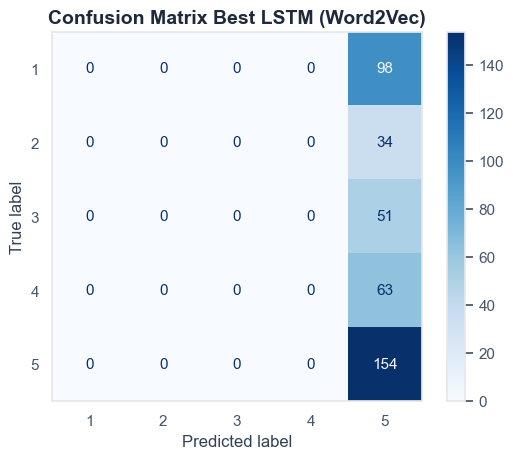

In [691]:
cm_dl_w2v_best = confusion_matrix(y_test, y_pred_dl_w2v_best_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dl_w2v_best, display_labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(6, 6))
disp.plot(values_format='d', cmap='Blues')
ax = plt.gca()
ax.grid(False)
plt.title("Confusion Matrix Best LSTM (Word2Vec)")
plt.show()